In [89]:
# importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [90]:
# Loading dataset and inspecting it
df = pd.read_csv('healthcare-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [91]:
# Checking datatypes of each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [92]:
# Checking fot null values
df.isnull().sum()
# BMI as 201 null values
# we could impute its values using mean, median etc
# or remove those rows altogether
# null value treatment to be done further in the code

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [93]:
# Checking for duplicated values
df.duplicated().sum()
# No duplicate values in the data

np.int64(0)

In [94]:
# Checking key values such as mean, standard deviation, quantiles etc for numerical columns
df.describe().round(3)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000,5110.000,5110.000,5110.000,5110.000,4909.000,5110.000
mean,36517.829,43.227,0.097,0.054,106.148,28.893,0.049
std,21161.722,22.613,0.297,0.226,45.284,7.854,0.215
min,67.000,0.080,0.000,0.000,55.120,10.300,0.000
25%,17741.250,25.000,0.000,0.000,77.245,23.500,0.000
50%,36932.000,45.000,0.000,0.000,91.885,28.100,0.000
75%,54682.000,61.000,0.000,0.000,114.090,33.100,0.000
max,72940.000,82.000,1.000,1.000,271.740,97.600,1.000


# EDA

In [95]:
# Checking the unique value for the possible columns
columns_unique = ['gender', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type','smoking_status', 'stroke']

for col in columns_unique:
    print(f"{col}: {df[col].unique()}")

gender: ['Male' 'Female' 'Other']
hypertension: [0 1]
heart_disease: [1 0]
ever_married: ['Yes' 'No']
work_type: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type: ['Urban' 'Rural']
smoking_status: ['formerly smoked' 'never smoked' 'smokes' 'Unknown']
stroke: [1 0]


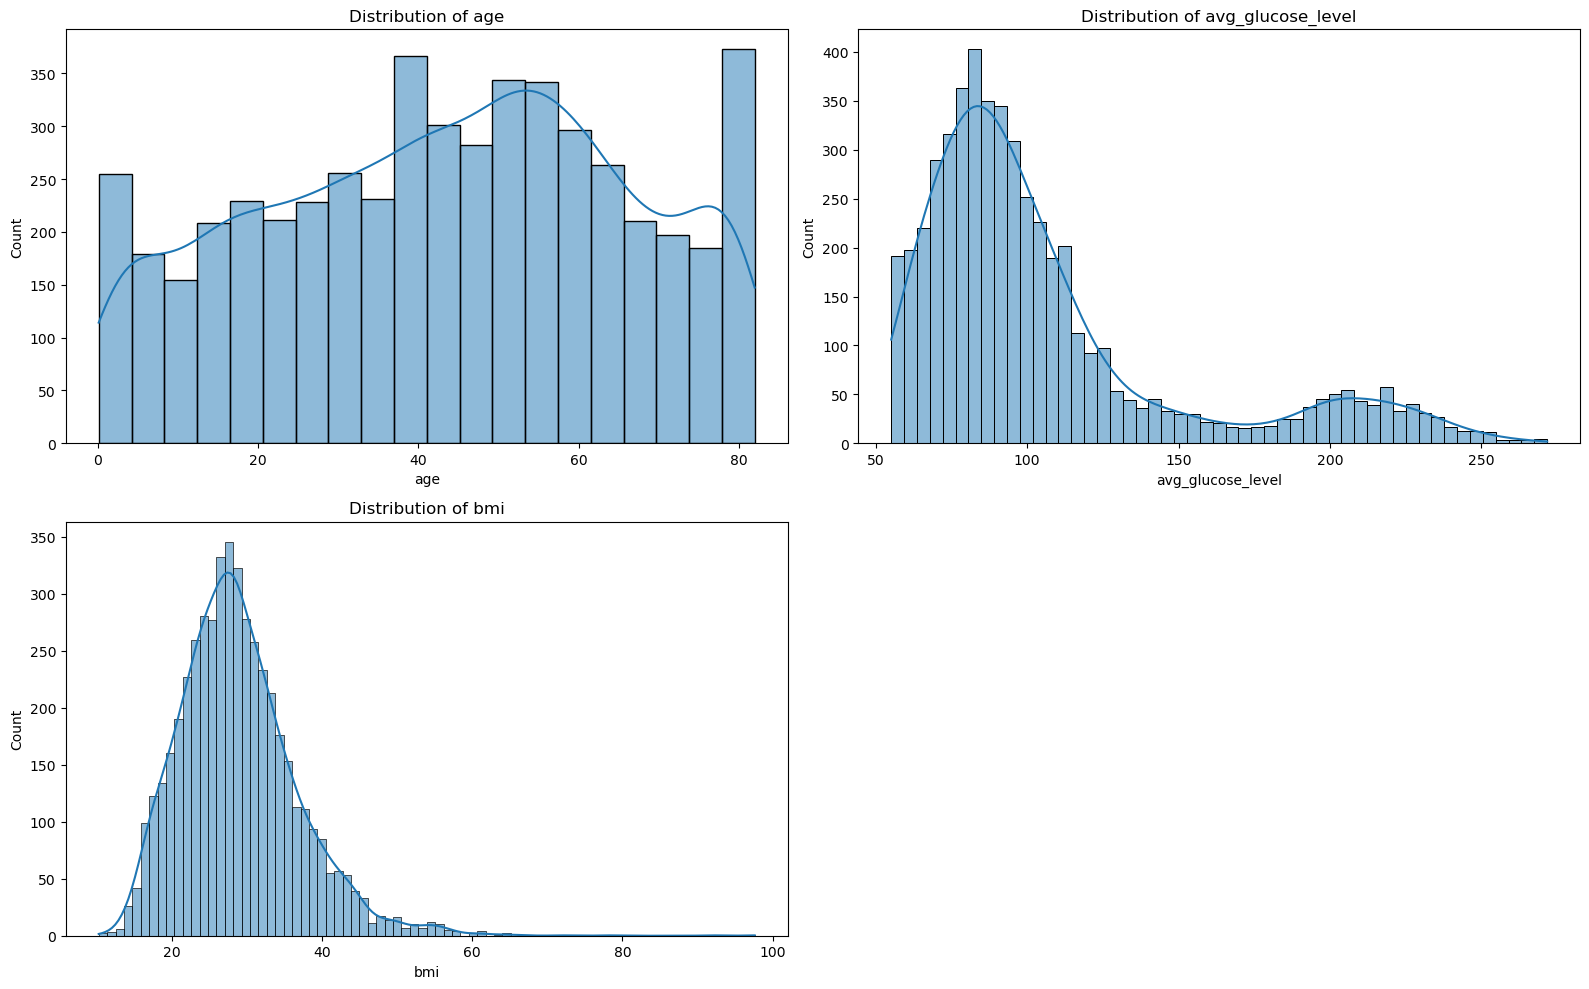

In [96]:
# Checking the distribution of numerical columns
numerical_cols = ["age","avg_glucose_level","bmi"]

plt.figure(figsize=(16,10))
for i,col in enumerate(numerical_cols):
    plt.subplot(2,2,i+1)
    sns.histplot(data=df,x=col,kde=True)
    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [97]:
# the variable age seems pretty evenly distributed,
# though ages above 40 seem to be observed more in the dataset
# no particular outliers/extreme ages in age

# strong positive skewness for avg_glucose_level
# higher values seems to be outliers or observed very less

# graph of bmi is right skewed with high number of observations being in between 20-35
# higher values og bmi might seem outliers but could prove to be useful for prediction

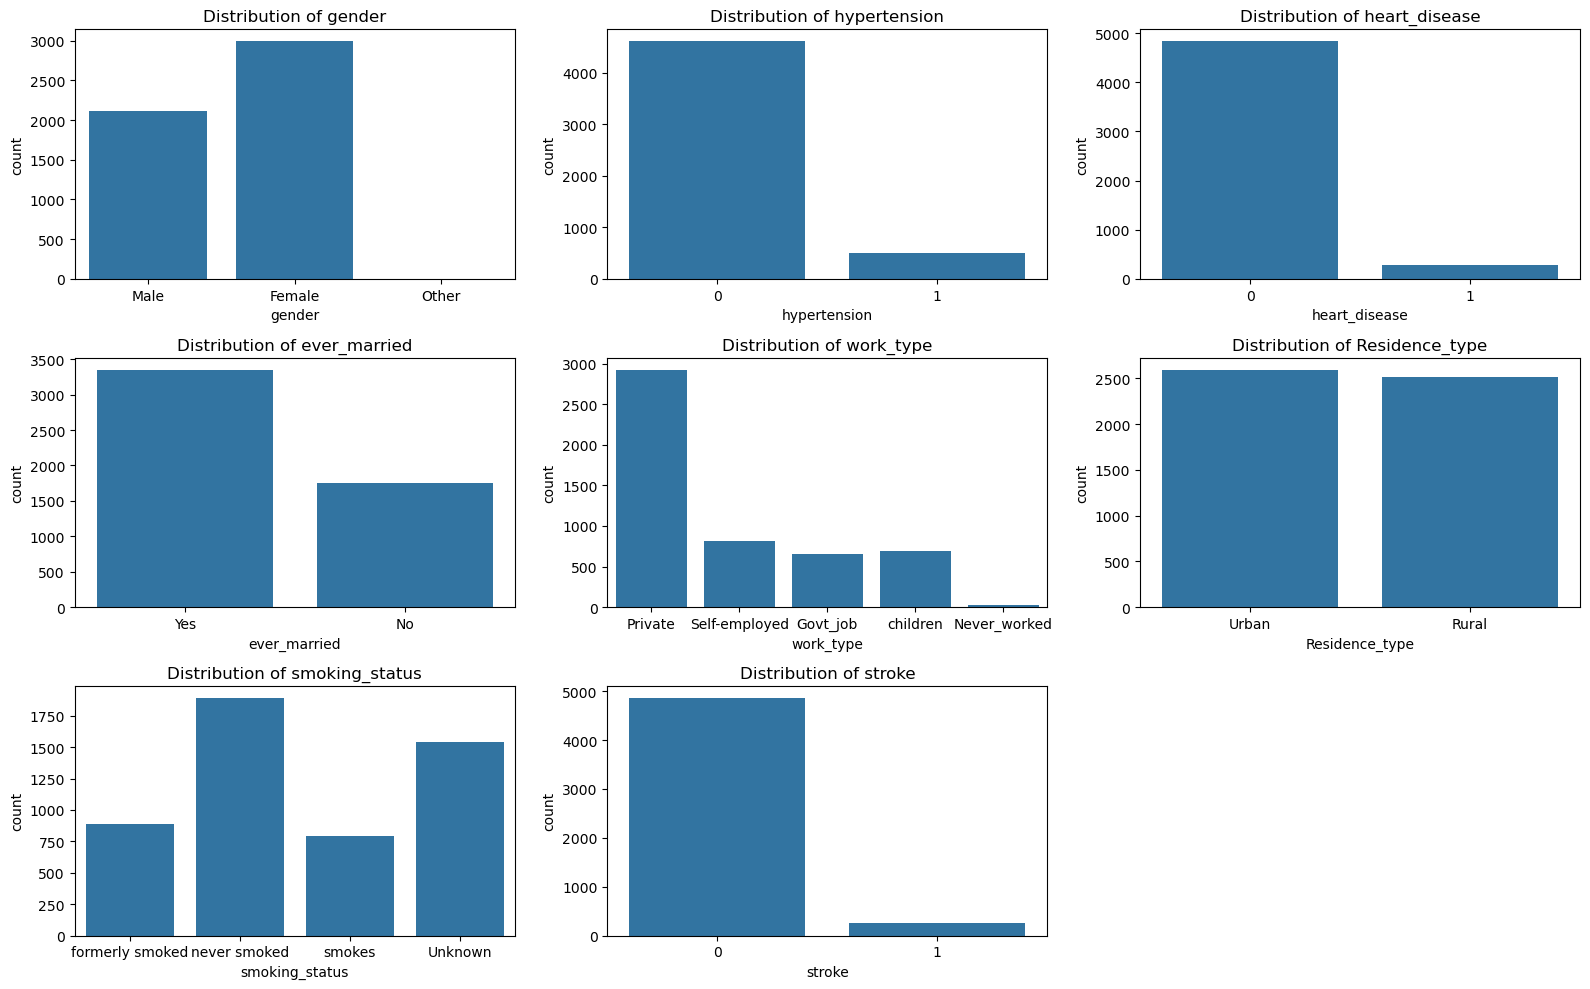

In [98]:
categorical_columns = ['gender','hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type','smoking_status', 'stroke']

plt.figure(figsize=(16,10))
for i,col in enumerate(categorical_columns):
       plt.subplot(3,3,i+1)
       sns.countplot(data=df,x=col)
       plt.title(f"Distribution of {col}")
       
plt.tight_layout()
plt.show()

In [99]:
# gender seems to have more observations for female than male
# although proportion of female in the dataset seems not to be very dominant

# for hypertension, heart_disease and stroke
# there seems to be high skewness in favour of people not having those particular features
# the low proportion of people having these features would make it tricky for the algorithm to make predictions

# data is evenly considering urban and rural population

# very little proportion of people who currently smoke
# significant population who isn't smoking currently (formerly smoking, never smoked or unknown)
# this is a crucial feature for prediction of

In [100]:
# Further analysis of target variable (stoke)
print(df['stroke'].value_counts(normalize=True)*100)
print("Roughly 5% of people who are likely to get stroke")
print("This is a small proportion in the dataset who are likely to suffer stroke")

stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64
Roughly 5% of people who are likely to get stroke
This is a small proportion in the dataset who are likely to suffer stroke


Fixing missing values in BMI

Text(0.5, 1.0, 'BMI: Median Imputed')

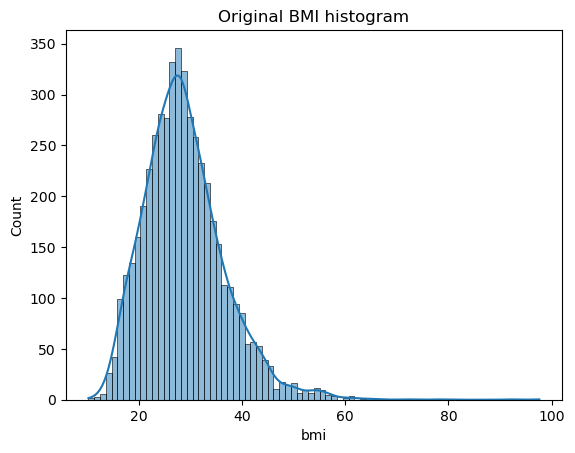

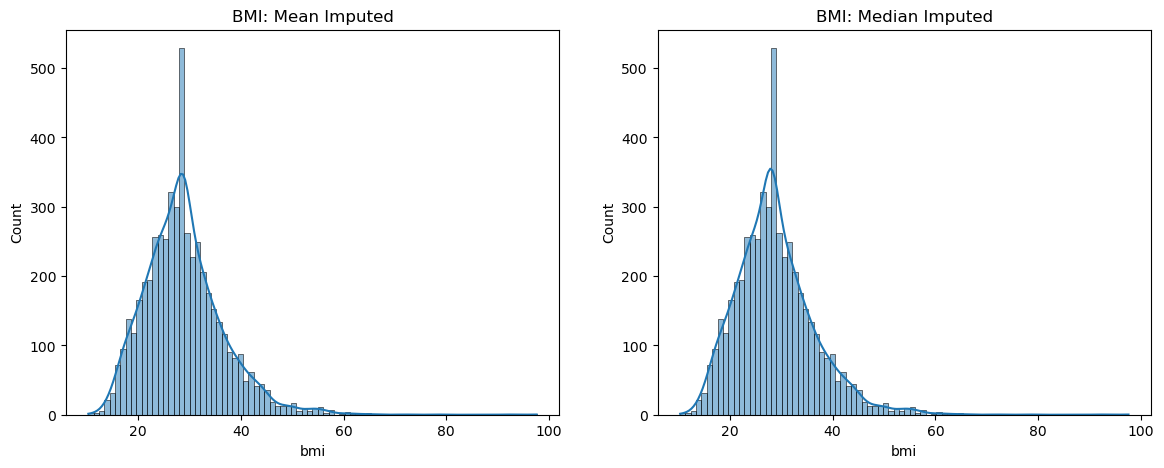

In [101]:
# the dataset contains roughly 5000 rows of informatin
# removing rows having missing values would lead to data having roughly 200 less rows
# this mean roughly 4% of the data would be removed
# so I would be imputing mean and median of the BMI and checking if it distorts the distribution of BMI column
sns.histplot(x=df['bmi'],kde=True)
plt.title("Original BMI histogram")

df_bmi_mean = df['bmi'].fillna(df['bmi'].mean())
df_bmi_median = df['bmi'].fillna(df['bmi'].median())

plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
sns.histplot(x=df_bmi_mean,kde=True)
plt.title("BMI: Mean Imputed")

plt.subplot(1,2,2)
sns.histplot(x=df_bmi_median,kde=True)
plt.title("BMI: Median Imputed")

# Both Mean and Median imputated graphs looks similar
# I would go with Median Imputed values

In [102]:
# Saving the Median Imputed values in dataset
df['bmi'] = df['bmi'].fillna(df['bmi'].median())

In [106]:
# Checking null values and datatype
print(f"Null values: {df.isnull().sum().sum()}")
df.info()

Null values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                5110 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


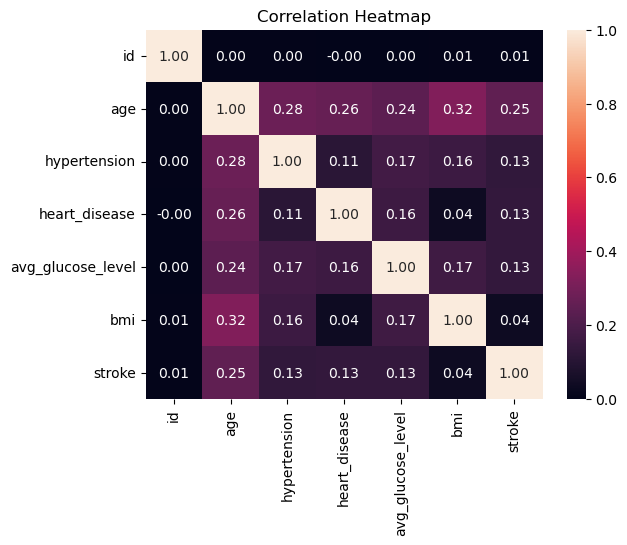

In [108]:
# Correlation Matrix (Numeric columns only)
sns.heatmap(df.corr(numeric_only=True),
            annot=True,fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [109]:
# No numeric column is negatively correlated to stroke or any other numeric columns
# all numeric variables seems to have weak to moderate positive correlation with stroke

# Data Preprocessing

In [111]:
X = df.drop(['id','stroke'],axis=1) # dropping target column and ID, ID is not useful for prediction
y = df['stroke'] # target column

In [ ]:
# Train Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
# using stratify as the number of stroke cases are less
# stratifying would ensure that training and tesing data has samples of both Yes and No cases of stroke

In [114]:
# OneHot Encoding the categorical columns
# Standard Scaling numerical columns so that extreme values do not create bias in the model
# using ColumnTransformer to do preprocess multiple columns at once

from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer

categorical_columns=['gender','ever_married','work_type','Residence_type','smoking_status']
numerical_cols = ['age','avg_glucose_level','bmi']
binary_cols = ['hypertension','heart_disease']

preprocessor = ColumnTransformer(
    transformers=[("cat",OneHotEncoder(drop='first',handle_unknown='ignore'),categorical_columns),
                  ("num",StandardScaler(),numerical_cols),
                  ("binary","passthrough",binary_cols)]
)

In [117]:
# Using a loop to fit Logistic Regression, KNN, DecisionTree and SVM

# Importing the required libraries
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Creating a dictionary of the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC()
}

In [122]:
# Fitting each model using a loop and Pipeline and calculating metrics
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score

results=[] # we would be storing the metrics in this

for name,model in models.items():
    
    # Creating a pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor",preprocessor),
        ("classifier",model)
    ])
    
    # Fitting the model
    pipeline.fit(X_train,y_train)
    
    # Predictions
    y_pred = pipeline.predict(X_test)
    
    # Calcuating metrics
    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred,zero_division=0)
    recall = recall_score(y_test,y_pred,zero_division=0)
    f1 = f1_score(y_test,y_pred,zero_division=0)
    
    # Store Results
    results.append({"Model": name,
                    "Accuracy": accuracy,
                    "Precision": precision,
                    "Recall": recall,
                    "F1 Score": f1})
    
    print(f"{name} fitted successfully")

Logistic Regression fitted successfully
KNN fitted successfully
Decision Tree fitted successfully
SVM fitted successfully


In [124]:
# Converting and displaying results in a table
results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9521,1.0000,0.02,0.0392
1,KNN,0.9432,0.0000,0.00,0.0000
2,Decision Tree,0.9100,0.1613,0.20,0.1786
3,SVM,0.9511,0.0000,0.00,0.0000


In [125]:
# Interpretation of the Metric Table

# Accuracy: How many predcitions were correct
# Logistic Regression and SVM has the highest Accuracy
# Decision Tree has the lowest Accuracy score

# Precision: Out of all yes by model, how many are actually right
# KNN and SVM did not produce any correct positive predictions
# Logistic Regression got all correct for which it said 'yes' to stroke
# Decision Tree got 16.13% correct of its 'yes' to stroke

# Recall: Out of all yes in reality, how many did model get right
# this is the most important metric because it is important to find actual stroke cases
# KNN and SVM could not get any actual stroke cases right
# Logistic Regression got 2% of actual cases right
# Decision Tree performed the best with getting 20% of actual cases right

# F1 Score: Tries to give a result which balances Precision and Recall
# for KNN and SVM it is 0, due to 0 recall and precision for both
# Here, Decision Tree gives the best result as well

# Overall, DecisionTree comes out to be a good prediction model
# even though it has the lowest of the Accuracy Score among the compared models
# THe model could be improved further my tuning its parameters

Hyperparameter Tuning for Decision Tree

In [126]:
# We would be doing Randomised Search Cross Validation as a starting point
from sklearn.model_selection import RandomizedSearchCV

dt_pipeline = Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("classifier",DecisionTreeClassifier(random_state=42))
])

param_dist = {
    "classifier__max_depth": [5, 7, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [2, 5, 10, 20],
    "classifier__criterion": ["gini", "entropy"],
    "classifier__class_weight": [None, "balanced"]
}

random_search_dt = RandomizedSearchCV(
    estimator=dt_pipeline,
    param_distributions=param_dist,
    n_iter=12,
    scoring="recall",
    cv=5,
    n_jobs=1,
    random_state=42,
    verbose=1
)

random_search_dt.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning:

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('cat',
                                                                               OneHotEncoder(drop='first',
                                                                                             handle_unknown='ignore'),
                                                                               ['gender',
                                                                                'ever_married',
                                                                                'work_type',
                                                                                'Residence_type',
                                                                                'smoking_status']),
                                                                              ('num',
                                                                               StandardScaler(),
                                                                               ['age',
                                                                                'avg_glucose_level',
                                                                                'bmi']),
                                                                              ('binary',
                                                                               'passthrough',
                                                                               ['hypertension',
                                                                                'heart_disease'])])),
                                             ('classifier',
                                              DecisionTreeClassifier(random_state=42))]),
                   n_iter=12, n_jobs=1,
                   param_distributions={'classifier__class_weight': [None,
                                                                     'balanced'],
                                        'classifier__criterion': ['gini',
                                                                  'entropy'],
                                        'classifier__max_depth': [5, 7, 10, 15,
                                                                  None],
                                        'classifier__min_samples_leaf': [2, 5,
                                                                         10,
                                                                         20],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10,
                                                                          20]},
                   random_state=42, scoring='recall', verbose=1)

In [130]:
# Checking the best hyperparameters
print(f"Best Parameters:")
random_search_dt.best_params_

Best Parameters:


{'classifier__min_samples_split': 2,
 'classifier__min_samples_leaf': 5,
 'classifier__max_depth': 5,
 'classifier__criterion': 'entropy',
 'classifier__class_weight': 'balanced'}

In [132]:
# Getting the best model
best_dt = random_search_dt.best_estimator_

# Predicting using the best model
y_pred_best_dt = best_dt.predict(X_test)

In [138]:
# Calculating metrics for Best model
print("Accuracy:", round(accuracy_score(y_test, y_pred_best_dt),4))
print("Precision:", round(precision_score(y_test, y_pred_best_dt, zero_division=0),4))
print("Recall:", round(recall_score(y_test, y_pred_best_dt, zero_division=0),4))
print("F1 Score:", round(f1_score(y_test, y_pred_best_dt, zero_division=0),4))

Accuracy: 0.6135
Precision: 0.0863
Recall: 0.72
F1 Score: 0.1542


In [ ]:
results.append({"Model": "Best Decision Tree",
                "Accuracy": round(accuracy_score(y_test, y_pred_best_dt),4),
                "Precision": round(precision_score(y_test, y_pred_best_dt, zero_division=0),4),
                "Recall": round(recall_score(y_test, y_pred_best_dt, zero_division=0),4),
                "F1 Score": round(f1_score(y_test, y_pred_best_dt, zero_division=0),4)})

In [ ]:
results_df = pd.DataFrame(results)

In [144]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.952055,1.00000,0.02,0.039216
1,KNN,0.943249,0.00000,0.00,0.000000
2,Decision Tree,0.909980,0.16129,0.20,0.178571
3,SVM,0.951076,0.00000,0.00,0.000000
4,Best Decision Tree,0.613500,0.08630,0.72,0.154200


In [ ]:
# The tuned Decision Tree has massively increased the recall
# i.e. it can correctly predict the actual stroke cases
# but it has come at a cost of lower accuracy, lower precision and thus lower F1 score

Conclusions and Interpretations

In [147]:
# The original Decision Tree achieved a recall of 20% and an F1 score of
#  17.86%, providing a better balance between identifying stroke cases
#  and avoiding false-positive predictions than the other models

# Hyperparameter tuning of the Decision Tree improved recall to 72%.
# However, precision decreased to 8.63%, while accuracy fell to 61.35%
# This illustrates the trade-off between identifying more actual stroke
# cases and generating more false-positive predictions

# Overall, no model demonstrated consistently strong performance across all evaluation metrics

Limitations and Drawbacks

In [148]:
# Class Imbalance: The dataset contains very few stroke cases, making it
# difficult for models to learn patterns associated with stroke occurrence

# Limited Algorithms: Only Logistic Regression, KNN, Decision Tree, and
# SVM were evaluated. Other algorithms might produce better results

# Hyperparameter Tuning: The search covered only a limited selection of
# parameter combinations due to computational constraints

Future Improvements

In [150]:
# Explore more advanced algorithms, such as Random Forest, XGBoost and Gradient Boosting

# Perform more extensive hyperparameter tuning using GridSearchCV or RandomizedSearchCV

# Evaluate model performance using additional metrics such as ROC-AUC, along with confusion matrices and F1 score